In [ ]:
%pip install -U importlib_resources

In [ ]:
"""
CS3807 Deep Learning Lab — Experiments 8 & 9
Effect of Attention Type and Attention Position in ImageNet-pretrained ResNet50.

Dataset: TensorFlow Flowers (5 classes)
Split: 70% train / 15% validation / 15% test (fixed, deterministic)
Framework: TensorFlow / Keras

IMPORTANT:
- This script performs real training. Do not replace its output metrics with guessed values.
- First run downloads TensorFlow Flowers and ImageNet ResNet50 weights.
- Full ablation runs can take hours and require a GPU. Set RUN_EXTENDED = False for the
  minimum mandatory set; set EPOCHS / FINETUNE_EPOCHS lower for a smoke test.
- Results, plots, model weights and qualitative visualizations are written to ./results/.
"""

import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import json
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

# ----------------------------- 1. CONFIGURATION -----------------------------

SEED = 42
IMG_SIZE = 224
NUM_CLASSES = 5
BATCH_SIZE = 16
EPOCHS = 5
FINETUNE_EPOCHS = 2
HEAD_LR = 1e-3
FINETUNE_LR = 1e-5
DROPOUT_RATE = 0.3
CHANNEL_REDUCTION = 16
SELF_ATTENTION_REDUCTION = 8
SPATIAL_KERNEL = 7
TOP_K_CHANNELS = 10

# False runs the core mandatory set plus the extra mechanisms and kernel study.
# True also runs optional multi-stage, order, kernel-size, and combined-attention ablations.
RUN_EXTENDED = True

OUT = Path("results")
MODELS_DIR = OUT / "models"
PLOTS_DIR = OUT / "plots"
VIS_DIR = OUT / "visualizations"
for folder in (OUT, MODELS_DIR, PLOTS_DIR, VIS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

print("TensorFlow:", tf.__version__)
print("Devices:", tf.config.list_physical_devices())
if not tf.config.list_physical_devices("GPU"):
    print("WARNING: No GPU detected. Training all experiments on CPU may take a long time.")

CLASS_NAMES = ["daisy", "dandelion", "roses", "sunflowers", "tulips"]

# ResNet50 stage endpoints (P1 is conv2_x, P2 conv3_x, P3 conv4_x, P4 conv5_x).
STAGE_LAYERS = {
    "P1": "conv2_block3_out",  # 56x56x256
    "P2": "conv3_block4_out",  # 28x28x512
    "P3": "conv4_block6_out",  # 14x14x1024
    "P4": "conv5_block3_out",  # 7x7x2048
}
STAGE_SHAPES = {
    "P1": (56, 56, 256),
    "P2": (28, 28, 512),
    "P3": (14, 14, 1024),
    "P4": (7, 7, 2048),
}


# ----------------------------- 2. DATASET ------------------------------------

def load_flowers():
    """Load one deterministic 70:15:15 split from the TFDS train split."""
    global CLASS_NAMES
    print("\nLoading TensorFlow Flowers (first run may download data)...")
    (train_raw, val_raw, test_raw), info = tfds.load(
        "tf_flowers",
        split=["train[:70%]", "train[70%:85%]", "train[85%:]"],
        as_supervised=True,
        with_info=True,
        shuffle_files=False,
    )
    # Verify the five classes and keep the manual's canonical class names.
    # Use the dataset's actual label-index order; this prevents class-name mismatches
    # in confusion matrices and classification reports.
    CLASS_NAMES = list(info.features["label"].names)
    total_examples = info.splits["train"].num_examples
    print("Class index order:", CLASS_NAMES)
    print("TFDS examples:", total_examples)
    print("Expected split sizes (approximately):",
          int(total_examples * 0.70), int(total_examples * 0.15),
          total_examples - int(total_examples * 0.70) - int(total_examples * 0.15))

    def resize_only(image, label):
        image = tf.image.resize(tf.cast(image, tf.float32), (IMG_SIZE, IMG_SIZE))
        label = tf.cast(label, tf.int32)
        return image, label

    options = tf.data.Options()
    options.experimental_deterministic = True

    train_ds = (train_raw.with_options(options)
                .map(resize_only, num_parallel_calls=tf.data.AUTOTUNE)
                .shuffle(1024, seed=SEED, reshuffle_each_iteration=True)
                .batch(BATCH_SIZE)
                .prefetch(tf.data.AUTOTUNE))
    val_ds = (val_raw.with_options(options)
              .map(resize_only, num_parallel_calls=tf.data.AUTOTUNE)
              .batch(BATCH_SIZE)
              .prefetch(tf.data.AUTOTUNE))
    test_ds = (test_raw.with_options(options)
               .map(resize_only, num_parallel_calls=tf.data.AUTOTUNE)
               .batch(BATCH_SIZE)
               .prefetch(tf.data.AUTOTUNE))

    # Cache a deterministic, non-augmented copy of test data for visualization.
    test_images, test_labels = [], []
    for xb, yb in test_ds:
        test_images.append(xb.numpy())
        test_labels.append(yb.numpy())
    test_images = np.concatenate(test_images)
    test_labels = np.concatenate(test_labels)

    # Required sample-image grid across all five classes.
    fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(15, 4))
    shown = set()
    for images, labels in train_ds.take(20):
        for image, label in zip(images.numpy(), labels.numpy()):
            label = int(label)
            if label not in shown:
                axes[label].imshow(np.clip(image / 255.0, 0, 1))
                axes[label].set_title(CLASS_NAMES[label])
                axes[label].axis("off")
                shown.add(label)
        if len(shown) == NUM_CLASSES:
            break
    fig.suptitle("TensorFlow Flowers: one training example per class")
    fig.tight_layout()
    fig.savefig(VIS_DIR / "sample_images_all_classes.png", dpi=160)
    plt.close(fig)

    split_info = {
        "dataset": "tf_flowers",
        "class_names": CLASS_NAMES,
        "train": int(info.splits["train"].num_examples * 0.70),
        "validation": int(info.splits["train"].num_examples * 0.15),
        "test": int(info.splits["train"].num_examples -
                    int(info.splits["train"].num_examples * 0.70) -
                    int(info.splits["train"].num_examples * 0.15)),
        "seed": SEED,
        "image_size": [IMG_SIZE, IMG_SIZE, 3],
    }
    with open(OUT / "dataset_split.json", "w", encoding="utf-8") as f:
        json.dump(split_info, f, indent=2)
    return train_ds, val_ds, test_ds, test_images, test_labels


# ----------------------------- 3. ATTENTION MODULES --------------------------

def channel_attention(x, prefix, reduction=CHANNEL_REDUCTION):
    channels = int(x.shape[-1])
    hidden = max(channels // reduction, 8)
    descriptor = layers.GlobalAveragePooling2D(keepdims=True, name=f"{prefix}_channel_gap")(x)
    descriptor = layers.Conv2D(hidden, 1, activation="relu",
                               name=f"{prefix}_channel_reduce")(descriptor)
    weights = layers.Conv2D(channels, 1, activation="sigmoid",
                            name=f"{prefix}_channel_weights")(descriptor)
    refined = layers.Multiply(name=f"{prefix}_channel_refined")([x, weights])
    return refined, weights


def spatial_attention(x, prefix, kernel_size=SPATIAL_KERNEL):
    avg_map = layers.Lambda(lambda t: tf.reduce_mean(t, axis=-1, keepdims=True),
                            name=f"{prefix}_spatial_avg")(x)
    max_map = layers.Lambda(lambda t: tf.reduce_max(t, axis=-1, keepdims=True),
                            name=f"{prefix}_spatial_max")(x)
    joined = layers.Concatenate(axis=-1, name=f"{prefix}_spatial_concat")([avg_map, max_map])
    weights = layers.Conv2D(1, kernel_size, padding="same", activation="sigmoid",
                            use_bias=False, name=f"{prefix}_spatial_weights")(joined)
    refined = layers.Multiply(name=f"{prefix}_spatial_refined")([x, weights])
    return refined, weights


def channel_spatial_attention(x, prefix, order="CS", kernel_size=SPATIAL_KERNEL):
    if order == "CS":
        x, channel_map = channel_attention(x, prefix)
        x, spatial_map = spatial_attention(x, prefix, kernel_size)
    elif order == "SC":
        x, spatial_map = spatial_attention(x, prefix, kernel_size)
        x, channel_map = channel_attention(x, prefix)
    else:
        raise ValueError("order must be 'CS' or 'SC'")
    return x, {"channel": channel_map, "spatial": spatial_map}


def se_attention(x, prefix, reduction=16):
    channels = int(x.shape[-1])
    hidden = max(channels // reduction, 8)
    z = layers.GlobalAveragePooling2D(keepdims=True, name=f"{prefix}_se_gap")(x)
    z = layers.Conv2D(hidden, 1, activation="relu", name=f"{prefix}_se_reduce")(z)
    weights = layers.Conv2D(channels, 1, activation="sigmoid", name=f"{prefix}_se_weights")(z)
    return layers.Multiply(name=f"{prefix}_se_refined")([x, weights]), {"channel": weights}


def eca_attention(x, prefix, gamma=2, b=1):
    channels = int(x.shape[-1])
    # ECA chooses a small odd 1-D convolution kernel based on channel count.
    t = int(abs((np.log2(channels) + b) / gamma))
    k = t if t % 2 else t + 1
    k = max(k, 3)
    z = layers.GlobalAveragePooling2D(keepdims=False, name=f"{prefix}_eca_gap")(x)
    z = layers.Reshape((channels, 1), name=f"{prefix}_eca_reshape_in")(z)
    z = layers.Conv1D(1, kernel_size=k, padding="same", use_bias=False,
                     name=f"{prefix}_eca_conv")(z)
    z = layers.Activation("sigmoid", name=f"{prefix}_eca_sigmoid")(z)
    z = layers.Reshape((1, 1, channels), name=f"{prefix}_eca_weights")(z)
    out = layers.Multiply(name=f"{prefix}_eca_refined")([x, z])
    return out, {"channel": z}


def self_attention(x, prefix, reduction=SELF_ATTENTION_REDUCTION):
    """Lightweight spatial self-attention. Used at P3/P4 to control N x N cost."""
    channels = int(x.shape[-1])
    d = max(channels // reduction, 32)
    q = layers.Conv2D(d, 1, use_bias=False, name=f"{prefix}_sa_query")(x)
    k = layers.Conv2D(d, 1, use_bias=False, name=f"{prefix}_sa_key")(x)
    v = layers.Conv2D(d, 1, use_bias=False, name=f"{prefix}_sa_value")(x)
    q = layers.Reshape((-1, d), name=f"{prefix}_sa_query_flat")(q)
    k = layers.Reshape((-1, d), name=f"{prefix}_sa_key_flat")(k)
    v = layers.Reshape((-1, d), name=f"{prefix}_sa_value_flat")(v)
    # QK^T / sqrt(d); at P3 N=196, P4 N=49.
    scores = layers.Lambda(
        lambda tensors: tf.matmul(tensors[0], tensors[1], transpose_b=True) /
                        tf.sqrt(tf.cast(d, tf.float32)),
        name=f"{prefix}_sa_scores"
    )([q, k])
    attention = layers.Softmax(axis=-1, name=f"{prefix}_sa_attention")(scores)
    response = layers.Lambda(lambda tensors: tf.matmul(tensors[0], tensors[1]),
                             name=f"{prefix}_sa_response")([attention, v])
    h, w = int(x.shape[1]), int(x.shape[2])
    response = layers.Reshape((h, w, d), name=f"{prefix}_sa_unflatten")(response)
    response = layers.Conv2D(channels, 1, use_bias=False, name=f"{prefix}_sa_project")(response)
    # A serializable Keras layer performs the scaled residual with a learnable gamma.
    class ScaledResidual(layers.Layer):
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
        def build(self, input_shape):
            self.gamma = self.add_weight(name="gamma", shape=(), initializer="zeros", trainable=True)
        def call(self, inputs):
            return inputs[0] + self.gamma * inputs[1]
    out = ScaledResidual(name=f"{prefix}_sa_residual")([x, response])
    return out, {"self": attention, "response": response}


def cbam_attention(x, prefix, kernel_size=7):
    # CBAM = channel attention followed by spatial attention.
    x, channel_map = channel_attention(x, f"{prefix}_cbam")
    x, spatial_map = spatial_attention(x, f"{prefix}_cbam", kernel_size)
    return x, {"channel": channel_map, "spatial": spatial_map}


def apply_attention(x, kind, prefix, kernel_size=SPATIAL_KERNEL):
    if kind == "none":
        return x, {}
    if kind == "channel":
        out, weights = channel_attention(x, prefix)
        return out, {"channel": weights}
    if kind == "spatial":
        out, weights = spatial_attention(x, prefix, kernel_size)
        return out, {"spatial": weights}
    if kind == "cs":
        return channel_spatial_attention(x, prefix, "CS", kernel_size)
    if kind == "sc":
        return channel_spatial_attention(x, prefix, "SC", kernel_size)
    if kind == "self":
        return self_attention(x, prefix)
    if kind == "combined":
        out, maps = channel_spatial_attention(x, prefix, "CS", kernel_size)
        out, self_maps = self_attention(out, f"{prefix}_combined")
        maps.update(self_maps)
        return out, maps
    if kind == "se":
        return se_attention(x, prefix)
    if kind == "eca":
        return eca_attention(x, prefix)
    if kind == "cbam":
        return cbam_attention(x, prefix, kernel_size)
    raise ValueError(f"Unknown attention kind: {kind}")


# ----------------------------- 4. MODEL BUILDER ------------------------------

def make_model(name, attention_by_stage=None, kernel_size=SPATIAL_KERNEL):
    """
    Build ResNet50 as stage segments so attention can be inserted after P1/P2/P3/P4.
    attention_by_stage example: {'P3': 'cs'}.
    """
    attention_by_stage = attention_by_stage or {}
    backbone = ResNet50(include_top=False, weights="imagenet",
                        input_shape=(IMG_SIZE, IMG_SIZE, 3))
    # Stage models share the exact pretrained ResNet50 layer weights.
    stage_tensors = {stage: backbone.get_layer(layer_name).output
                     for stage, layer_name in STAGE_LAYERS.items()}
    segment_names = ["P1", "P2", "P3", "P4"]
    stem = Model(backbone.input, stage_tensors["P1"], name=f"{name}_stem_to_P1")
    segments = {}
    for left, right in zip(segment_names[:-1], segment_names[1:]):
        segments[(left, right)] = Model(
            stage_tensors[left], stage_tensors[right],
            name=f"{name}_{left}_to_{right}"
        )

    image_input = layers.Input((IMG_SIZE, IMG_SIZE, 3), name=f"{name}_image")
    x = layers.RandomFlip("horizontal", seed=SEED, name=f"{name}_aug_flip")(image_input)
    x = layers.RandomRotation(0.04, seed=SEED, name=f"{name}_aug_rotate")(x)
    x = layers.RandomZoom(0.08, seed=SEED, name=f"{name}_aug_zoom")(x)
    x = layers.RandomTranslation(0.05, 0.05, seed=SEED, name=f"{name}_aug_translate")(x)
    x = layers.RandomContrast(0.1, seed=SEED, name=f"{name}_aug_contrast")(x)
    x = layers.Lambda(preprocess_input, name=f"{name}_resnet_preprocess")(x)

    x = stem(x)
    attention_maps = {}
    feature_before = {}
    feature_after = {}
    for idx, stage in enumerate(segment_names):
        if stage in attention_by_stage:
            feature_before[stage] = x
            x, maps = apply_attention(
                x, attention_by_stage[stage],
                prefix=f"{name}_{stage}",
                kernel_size=kernel_size
            )
            feature_after[stage] = x
            for map_type, tensor in maps.items():
                attention_maps[f"{stage}_{map_type}"] = tensor
        if idx < len(segment_names) - 1:
            x = segments[(stage, segment_names[idx + 1])](x)

    x = layers.GlobalAveragePooling2D(name=f"{name}_global_average_pool")(x)
    x = layers.Dropout(DROPOUT_RATE, seed=SEED, name=f"{name}_dropout")(x)
    output = layers.Dense(NUM_CLASSES, activation="softmax", name=f"{name}_predictions")(x)
    model = Model(image_input, output, name=name)

    # Freeze all backbone layers for head training.
    for layer in backbone.layers:
        layer.trainable = False

    # Save stage feature outputs for feature-map visualization.
    feature_tensors = {}
    for stage in segment_names:
        feature_tensors[f"{stage}_before"] = feature_before.get(stage)
        feature_tensors[f"{stage}_after"] = feature_after.get(stage)
    return model, backbone, attention_maps, feature_tensors


def unfreeze_final_stage(backbone):
    """Fine-tune conv5_x while leaving earlier pretrained stages frozen."""
    for layer in backbone.layers:
        layer.trainable = layer.name.startswith("conv5_") or layer.name.startswith("post_bn")
    # Keep batch-normalization statistics frozen for a small dataset.
    for layer in backbone.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False


# ----------------------------- 5. TRAINING / EVALUATION ----------------------

def compile_model(model, learning_rate):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )


def train_model(model, backbone, name, train_ds, val_ds):
    weight_path = MODELS_DIR / f"{name}.weights.h5"
    history_frames = []
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            str(weight_path), monitor="val_accuracy", mode="max",
            save_best_only=True, save_weights_only=True, verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=2, restore_best_weights=True, verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.3, patience=1, min_lr=1e-7, verbose=1
        ),
    ]

    compile_model(model, HEAD_LR)
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                   callbacks=callbacks, verbose=1)
    for key, values in h1.history.items():
        for epoch, value in enumerate(values, start=1):
            history_frames.append({"model": name, "phase": "frozen_head",
                                   "epoch": epoch, "metric": key, "value": float(value)})

    # Fine-tune final ResNet stage at a smaller learning rate.
    unfreeze_final_stage(backbone)
    compile_model(model, FINETUNE_LR)
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=FINETUNE_EPOCHS,
                   callbacks=callbacks, verbose=1)
    offset = len(h1.history.get("loss", []))
    for key, values in h2.history.items():
        for epoch, value in enumerate(values, start=1):
            history_frames.append({"model": name, "phase": "fine_tune",
                                   "epoch": offset + epoch, "metric": key, "value": float(value)})

    if weight_path.exists():
        model.load_weights(weight_path)
    hist_df = pd.DataFrame(history_frames)
    hist_df.to_csv(OUT / f"{name}_history.csv", index=False)
    return hist_df


def infer_metrics(model, test_ds, name, test_images, test_labels):
    # Warm-up + timed inference on batches; report average milliseconds per image.
    for xb, _ in test_ds.take(1):
        _ = model(xb, training=False)
    start = time.perf_counter()
    predictions = []
    labels = []
    for xb, yb in test_ds:
        probs = model(xb, training=False).numpy()
        predictions.extend(np.argmax(probs, axis=1).tolist())
        labels.extend(yb.numpy().tolist())
    elapsed = time.perf_counter() - start
    y_pred = np.asarray(predictions)
    y_true = np.asarray(labels)
    metrics = {
        "model": name,
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_macro": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "total_parameters": int(model.count_params()),
        "trainable_parameters": int(sum(np.prod(w.shape) for w in model.trainable_weights)),
        "inference_ms_per_image": float(1000 * elapsed / max(len(y_true), 1)),
    }
    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    np.save(OUT / f"{name}_y_true.npy", y_true)
    np.save(OUT / f"{name}_y_pred.npy", y_pred)
    pd.DataFrame(classification_report(
        y_true, y_pred, labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES, output_dict=True, zero_division=0
    )).transpose().to_csv(OUT / f"{name}_classification_report.csv")
    return metrics, cm, y_pred


def plot_confusion(cm, name):
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm, interpolation="nearest")
    ax.figure.colorbar(im, ax=ax)
    ax.set(
        xticks=np.arange(NUM_CLASSES), yticks=np.arange(NUM_CLASSES),
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
        xlabel="Predicted label", ylabel="True label",
        title=f"Confusion matrix — {name}"
    )
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right", rotation_mode="anchor")
    threshold = cm.max() / 2 if cm.size else 0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > threshold else "black")
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / f"{name}_confusion_matrix.png", dpi=180)
    plt.close(fig)


def plot_training_curves(history_csvs):
    all_history = []
    for path in history_csvs:
        if Path(path).exists():
            all_history.append(pd.read_csv(path))
    if not all_history:
        return
    df = pd.concat(all_history, ignore_index=True)
    for metric, title, filename in [
        ("accuracy", "Training accuracy", "training_accuracy_curves.png"),
        ("val_accuracy", "Validation accuracy", "validation_accuracy_curves.png"),
        ("loss", "Training loss", "training_loss_curves.png"),
        ("val_loss", "Validation loss", "validation_loss_curves.png"),
    ]:
        subset = df[df.metric == metric]
        if subset.empty:
            continue
        fig, ax = plt.subplots(figsize=(10, 6))
        for model_name, group in subset.groupby("model"):
            # Epochs can repeat between frozen and fine-tuning phases; sort by recorded epoch.
            group = group.sort_values("epoch")
            ax.plot(group["epoch"], group["value"], marker="o", label=model_name)
        ax.set_xlabel("Epoch")
        ax.set_ylabel(metric.replace("_", " ").title())
        ax.set_title(title)
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)
        fig.tight_layout()
        fig.savefig(PLOTS_DIR / filename, dpi=180)
        plt.close(fig)


# ----------------------------- 6. QUALITATIVE VISUALIZATIONS -----------------

def build_internal_output_model(model, tensor_dict):
    outputs, names = [], []
    for name, tensor in tensor_dict.items():
        if tensor is not None:
            outputs.append(tensor)
            names.append(name)
    if not outputs:
        return None, []
    return Model(model.input, outputs, name=f"{model.name}_internal_outputs"), names


def save_feature_map(model, tensor_dict, image, model_name):
    internal_model, names = build_internal_output_model(model, tensor_dict)
    if internal_model is None:
        return
    outputs = internal_model(np.expand_dims(image, 0), training=False)
    if not isinstance(outputs, (list, tuple)):
        outputs = [outputs]
    for name, tensor in zip(names, outputs):
        feature = tensor.numpy()[0]
        # Display mean absolute activation over channels to keep figures readable.
        activation = np.mean(np.abs(feature), axis=-1)
        activation = (activation - activation.min()) / (activation.max() - activation.min() + 1e-8)
        fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
        axes[0].imshow(np.clip(image / 255.0, 0, 1))
        axes[0].set_title("Input image")
        axes[1].imshow(activation, cmap="viridis")
        axes[1].set_title(f"{name}: mean |activation|")
        for ax in axes:
            ax.axis("off")
        fig.tight_layout()
        fig.savefig(VIS_DIR / f"{model_name}_{name}_feature_map.png", dpi=160)
        plt.close(fig)


def build_attention_map_model(model, attention_maps):
    items = [(name, tensor) for name, tensor in attention_maps.items() if tensor is not None]
    if not items:
        return None, []
    return Model(model.input, [tensor for _, tensor in items]), [name for name, _ in items]


def save_attention_visualizations(model, attention_maps, image, model_name):
    map_model, map_names = build_attention_map_model(model, attention_maps)
    if map_model is None:
        return
    values = map_model(np.expand_dims(image, 0), training=False)
    if not isinstance(values, (list, tuple)):
        values = [values]
    for map_name, tensor in zip(map_names, values):
        arr = tensor.numpy()[0]
        if "channel" in map_name and arr.ndim == 3 and arr.shape[0] == 1:
            weights = arr.reshape(-1)
            top = np.argsort(weights)[-TOP_K_CHANNELS:][::-1]
            fig, ax = plt.subplots(figsize=(8, 4))
            ax.bar([str(int(i)) for i in top], weights[top])
            ax.set_xlabel("Channel index")
            ax.set_ylabel("Attention weight")
            ax.set_title(f"Top {TOP_K_CHANNELS} channel weights — {map_name}")
            fig.tight_layout()
            fig.savefig(VIS_DIR / f"{model_name}_{map_name}_top_channels.png", dpi=160)
            plt.close(fig)
        elif "spatial" in map_name and arr.ndim == 3:
            spatial = arr[..., 0]
            spatial = tf.image.resize(spatial[None, ..., None], (IMG_SIZE, IMG_SIZE)).numpy()[0, ..., 0]
            fig, axes = plt.subplots(1, 3, figsize=(12, 4))
            axes[0].imshow(np.clip(image / 255.0, 0, 1))
            axes[0].set_title("Input")
            axes[1].imshow(spatial, cmap="jet")
            axes[1].set_title("Spatial attention")
            axes[2].imshow(np.clip(image / 255.0, 0, 1))
            axes[2].imshow(spatial, cmap="jet", alpha=0.45)
            axes[2].set_title("Overlay")
            for ax in axes:
                ax.axis("off")
            fig.tight_layout()
            fig.savefig(VIS_DIR / f"{model_name}_{map_name}_overlay.png", dpi=160)
            plt.close(fig)
        elif "self" in map_name and arr.ndim == 2:
            # Attention matrix is N x N. Visualize mean response received by each key position.
            response = np.mean(arr, axis=0)
            side = int(np.sqrt(response.size))
            if side * side == response.size:
                response = response.reshape(side, side)
                fig, ax = plt.subplots(figsize=(5, 4))
                im = ax.imshow(response, cmap="magma")
                fig.colorbar(im, ax=ax)
                ax.set_title(f"Self-attention response — {map_name}")
                ax.axis("off")
                fig.tight_layout()
                fig.savefig(VIS_DIR / f"{model_name}_{map_name}_response.png", dpi=160)
                plt.close(fig)


def gradcam(model, image, class_index=None, target_layer_name="conv5_block3_out"):
    """Grad-CAM using the output of the P3-to-P4 ResNet segment."""
    try:
        # The ResNet backbone is wrapped in stage-segment Models. The P3-to-P4
        # segment output is the conv5_x feature tensor and remains connected to logits.
        stage_segment = next(
            (layer for layer in model.layers
             if isinstance(layer, Model) and "P3_to_P4" in layer.name),
            None
        )
        if stage_segment is None:
            warnings.warn(f"No P3-to-P4 segment found for Grad-CAM: {model.name}")
            return None
        grad_model = Model(model.inputs, [stage_segment.output, model.output])
        img = tf.convert_to_tensor(np.expand_dims(image, 0), dtype=tf.float32)
        with tf.GradientTape() as tape:
            conv_outputs, predictions = grad_model(img, training=False)
            if class_index is None:
                class_index = int(tf.argmax(predictions[0]))
            class_score = predictions[:, class_index]
        grads = tape.gradient(class_score, conv_outputs)
        if grads is None:
            return None
        pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
        conv_outputs = conv_outputs[0]
        heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)
        heatmap = tf.maximum(heatmap, 0)
        heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
        heatmap = tf.image.resize(heatmap[None, ..., None], (IMG_SIZE, IMG_SIZE))[0, ..., 0].numpy()
        return heatmap
    except Exception as exc:
        warnings.warn(f"Grad-CAM could not be generated for {model.name}: {exc}")
        return None


def save_gradcam_comparison(models_for_cam, test_images, test_labels, predictions_by_model):
    # Prefer 3 correctly and 2 incorrectly classified samples from baseline, if available.
    baseline_name = "baseline"
    if baseline_name not in predictions_by_model:
        baseline_name = next(iter(predictions_by_model))
    y_pred = predictions_by_model[baseline_name]
    correct = np.where(y_pred == test_labels)[0][:3]
    wrong = np.where(y_pred != test_labels)[0][:2]
    chosen = list(correct) + list(wrong)
    if not chosen:
        chosen = list(range(min(5, len(test_images))))
    with open(OUT / "qualitative_sample_indices.json", "w", encoding="utf-8") as f:
        json.dump({"indices": [int(i) for i in chosen],
                   "baseline_correct_indices": [int(i) for i in correct],
                   "baseline_incorrect_indices": [int(i) for i in wrong]}, f, indent=2)

    for idx in chosen:
        image = test_images[idx]
        fig, axes = plt.subplots(1, len(models_for_cam) + 1,
                                 figsize=(4 * (len(models_for_cam) + 1), 4))
        if not isinstance(axes, np.ndarray):
            axes = np.array([axes])
        axes[0].imshow(np.clip(image / 255.0, 0, 1))
        axes[0].set_title(f"Input\nTrue: {CLASS_NAMES[int(test_labels[idx])]}")
        axes[0].axis("off")
        for ax, (model_name, model) in zip(axes[1:], models_for_cam.items()):
            pred = model(image[None, ...], training=False).numpy()[0]
            pred_class = int(np.argmax(pred))
            heatmap = gradcam(model, image, pred_class)
            ax.imshow(np.clip(image / 255.0, 0, 1))
            if heatmap is not None:
                ax.imshow(heatmap, cmap="jet", alpha=0.42)
            ax.set_title(f"{model_name}\nPred: {CLASS_NAMES[pred_class]}")
            ax.axis("off")
        fig.tight_layout()
        fig.savefig(VIS_DIR / f"gradcam_comparison_test_{idx}.png", dpi=160)
        plt.close(fig)


def save_stage_attention_position_plot(test_image):
    """Standalone visual comparison of CS spatial attention at P2/P3/P4."""
    position_models = {}
    for stage in ["P2", "P3", "P4"]:
        model, backbone, maps, _ = make_model(f"position_viz_{stage}", {stage: "cs"})
        # This visualization-only model has random attention weights unless trained.
        # It is explicitly labeled as untrained if the corresponding checkpoint is unavailable.
        ckpt = MODELS_DIR / f"channel_spatial_{stage}.weights.h5"
        if ckpt.exists():
            try:
                model.load_weights(ckpt)
            except Exception:
                pass
        position_models[stage] = (model, maps)

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes[0].imshow(np.clip(test_image / 255.0, 0, 1))
    axes[0].set_title("Input")
    axes[0].axis("off")
    for ax, stage in zip(axes[1:], ["P2", "P3", "P4"]):
        model, maps = position_models[stage]
        map_model, names = build_attention_map_model(model, maps)
        spatial_key = next((i for i, n in enumerate(names) if n == f"{stage}_spatial"), None)
        if spatial_key is None:
            # Locate spatial map generated by the module.
            spatial_key = next((i for i, n in enumerate(names) if "spatial" in n), None)
        if spatial_key is not None:
            vals = map_model(test_image[None, ...], training=False)
            if not isinstance(vals, (list, tuple)):
                vals = [vals]
            heat = vals[spatial_key].numpy()[0, ..., 0]
            heat = tf.image.resize(heat[None, ..., None], (IMG_SIZE, IMG_SIZE)).numpy()[0, ..., 0]
            ax.imshow(heat, cmap="jet")
        ax.set_title(f"{stage} spatial map\n(visualization model)")
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(VIS_DIR / "attention_position_P2_P3_P4.png", dpi=160)
    plt.close(fig)


# ----------------------------- 7. EXPERIMENT DEFINITIONS ---------------------

def experiments_to_run():
    # Mandatory core: baseline, channel P3, spatial P3, CS P2/P3/P4, self P3.
    experiments = [
        ("baseline", {}),
        ("channel_P3", {"P3": "channel"}),
        ("spatial_P3", {"P3": "spatial"}),
        ("channel_spatial_P2", {"P2": "cs"}),
        ("channel_spatial_P3", {"P3": "cs"}),
        ("channel_spatial_P4", {"P4": "cs"}),
        ("self_attention_P3", {"P3": "self"}),
        # Two additional established mechanisms required by the manual.
        ("SE_P3", {"P3": "se"}),
        ("ECA_P3", {"P3": "eca"}),
        ("CBAM_P3", {"P3": "cbam"}),
    ]
    if RUN_EXTENDED:
        experiments += [
            ("combined_attention_P3", {"P3": "combined"}),
            ("channel_spatial_P3_P4", {"P3": "cs", "P4": "cs"}),
            ("channel_spatial_P2_P3_P4", {"P2": "cs", "P3": "cs", "P4": "cs"}),
            ("spatial_channel_P3", {"P3": "sc"}),
            ("spatial_kernel3_P3", {"P3": "spatial"}),
            ("spatial_kernel5_P3", {"P3": "spatial"}),
        ]
    return experiments


# ----------------------------- 8. RESULT TABLES AND GRAPHS -------------------

def make_result_graphs(results_df):
    if results_df.empty:
        return
    # Accuracy and Macro F1 bars.
    for metric, title, filename in [
        ("accuracy", "Attention mechanism vs test accuracy", "attention_vs_accuracy.png"),
        ("macro_f1", "Attention mechanism vs macro F1", "attention_vs_macro_f1.png"),
    ]:
        fig, ax = plt.subplots(figsize=(12, 6))
        ordered = results_df.sort_values(metric, ascending=False)
        ax.bar(ordered["model"], ordered[metric])
        ax.set_ylabel(metric.replace("_", " ").title())
        ax.set_title(title)
        ax.tick_params(axis="x", labelrotation=65)
        ax.grid(axis="y", alpha=0.25)
        fig.tight_layout()
        fig.savefig(PLOTS_DIR / filename, dpi=180)
        plt.close(fig)

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.scatter(results_df["total_parameters"], results_df["accuracy"])
    for _, row in results_df.iterrows():
        ax.annotate(row["model"], (row["total_parameters"], row["accuracy"]),
                    fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.set_xlabel("Total parameters")
    ax.set_ylabel("Test accuracy")
    ax.set_title("Accuracy vs model parameters")
    ax.grid(True, alpha=0.25)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "accuracy_vs_parameters.png", dpi=180)
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.scatter(results_df["inference_ms_per_image"], results_df["macro_f1"])
    for _, row in results_df.iterrows():
        ax.annotate(row["model"], (row["inference_ms_per_image"], row["macro_f1"]),
                    fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.set_xlabel("Inference time (ms/image)")
    ax.set_ylabel("Macro F1")
    ax.set_title("Macro F1 vs inference time")
    ax.grid(True, alpha=0.25)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "macro_f1_vs_inference_time.png", dpi=180)
    plt.close(fig)


def make_kernel_table(results_df):
    # Kernel 7 is represented by the core spatial_P3 model; 3 and 5 by extended runs.
    mapping = {3: "spatial_kernel3_P3", 5: "spatial_kernel5_P3", 7: "spatial_P3"}
    rows = []
    for kernel, model_name in mapping.items():
        found = results_df[results_df["model"] == model_name]
        if len(found):
            row = found.iloc[0]
            rows.append({
                "spatial_kernel": f"{kernel}x{kernel}", "model": model_name,
                "accuracy": row["accuracy"], "macro_f1": row["macro_f1"],
                "inference_ms_per_image": row["inference_ms_per_image"]
            })
        else:
            rows.append({
                "spatial_kernel": f"{kernel}x{kernel}", "model": model_name,
                "accuracy": np.nan, "macro_f1": np.nan,
                "inference_ms_per_image": np.nan
            })
    pd.DataFrame(rows).to_csv(OUT / "spatial_kernel_comparison.csv", index=False)


# ----------------------------- 9. MAIN ---------------------------------------

def main():
    train_ds, val_ds, test_ds, test_images, test_labels = load_flowers()
    result_rows = []
    history_paths = []
    cam_models = {}
    predictions_by_model = {}
    trained_visual_models = {}

    experiments = experiments_to_run()
    print("\nExperiments queued:", len(experiments))
    for exp_index, (name, stage_config) in enumerate(experiments, start=1):
        print(f"\n{'=' * 80}\n[{exp_index}/{len(experiments)}] Training: {name} | attention={stage_config}\n{'=' * 80}")
        kernel_size = SPATIAL_KERNEL
        if name.startswith("spatial_kernel3"):
            kernel_size = 3
        elif name.startswith("spatial_kernel5"):
            kernel_size = 5

        model, backbone, attention_maps, feature_tensors = make_model(
            name, stage_config, kernel_size=kernel_size
        )
        print("Total parameters:", f"{model.count_params():,}")
        history = train_model(model, backbone, name, train_ds, val_ds)
        history_paths.append(OUT / f"{name}_history.csv")

        metrics, cm, y_pred = infer_metrics(model, test_ds, name, test_images, test_labels)
        metrics["attention_position"] = "+".join(stage_config.keys()) if stage_config else "-"
        metrics["attention_type"] = "+".join(stage_config.values()) if stage_config else "none"
        metrics["spatial_kernel"] = kernel_size if any(
            x in name for x in ["spatial", "CBAM", "channel_spatial", "combined"]
        ) else np.nan
        result_rows.append(metrics)
        predictions_by_model[name] = y_pred
        plot_confusion(cm, name)

        # Keep baseline and selected attention models in memory for qualitative comparisons.
        if name in ["baseline", "channel_spatial_P3"]:
            cam_models[name] = model
        if name in ["baseline", "channel_P3", "spatial_P3", "channel_spatial_P3",
                    "self_attention_P3"]:
            trained_visual_models[name] = (model, attention_maps, feature_tensors)

        # Save internal maps/feature maps for one representative test image.
        if name in ["channel_P3", "spatial_P3", "channel_spatial_P3", "self_attention_P3"]:
            save_attention_visualizations(model, attention_maps, test_images[0], name)
            save_feature_map(model, feature_tensors, test_images[0], name)

        # Release training graph memory between models.
        del model, backbone
        tf.keras.backend.clear_session()
        # Restore global seeds after clearing the session.
        tf.random.set_seed(SEED)

    results_df = pd.DataFrame(result_rows)
    results_df.to_csv(OUT / "main_results.csv", index=False)
    try:
        results_df.to_excel(OUT / "main_results.xlsx", index=False)
    except Exception as exc:
        print("Excel export skipped (install openpyxl to enable):", exc)
    print("\nFINAL TEST RESULTS")
    print(results_df.to_string(index=False))
    make_result_graphs(results_df)
    plot_training_curves(history_paths)
    make_kernel_table(results_df)

    # Grad-CAM comparison (models retained above; only selected two).
    if len(cam_models) >= 2:
        save_gradcam_comparison(cam_models, test_images, test_labels, predictions_by_model)

    # Position map illustration at P2/P3/P4 using the same test image.
    # These standalone maps are visualization-only unless a matching trained checkpoint is loaded.
    save_stage_attention_position_plot(test_images[0])

    # Required main result table in a compact lab-manual-style layout.
    table_columns = [
        "model", "attention_position", "accuracy", "precision_macro",
        "recall_macro", "macro_f1", "trainable_parameters",
        "total_parameters", "inference_ms_per_image"
    ]
    results_df[table_columns].to_csv(OUT / "required_main_result_table.csv", index=False)
    print(f"\nFinished. All outputs are in: {OUT.resolve()}")
    print("Important outputs:")
    print(" - results/main_results.csv and main_results.xlsx")
    print(" - results/required_main_result_table.csv")
    print(" - results/plots/*.png")
    print(" - results/visualizations/*.png")
    print(" - results/models/*.weights.h5")


if __name__ == "__main__":
    main()


TensorFlow: 2.21.0
Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Loading TensorFlow Flowers (first run may download data)...


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

...


[9/16] Training: ECA_P3 | attention={'P3': 'eca'}
Total parameters: 23,597,962
Epoch 1/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.4027 - loss: 1.4322
Epoch 1: val_accuracy improved from None to 0.74410, saving model to results/models/ECA_P3.weights.h5

Epoch 1: finished saving model to results/models/ECA_P3.weights.h5
161/161 ━━━━━━━━━━━━━━━━━━━━ 28s 128ms/step - accuracy: 0.5286 - loss: 1.2316 - val_accuracy: 0.7441 - val_loss: 0.7864 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.7862 - loss: 0.6759
Epoch 2: val_accuracy improved from 0.74410 to 0.84029, saving model to results/models/ECA_P3.weights.h5

Epoch 2: finished saving model to results/models/ECA_P3.weights.h5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 117ms/step - accuracy: 0.7902 - loss: 0.6122 - val_accuracy: 0.8403 - val_loss: 0.4398 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.8397 - loss: 0.4342
Epoch 3: val_accuracy improved 

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 66 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))



[12/16] Training: channel_spatial_P3_P4 | attention={'P3': 'cs', 'P4': 'cs'}
Total parameters: 24,256,777
Epoch 1/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - accuracy: 0.6556 - loss: 0.8851
Epoch 1: val_accuracy improved from None to 0.86388, saving model to results/models/channel_spatial_P3_P4.weights.h5

Epoch 1: finished saving model to results/models/channel_spatial_P3_P4.weights.h5
161/161 ━━━━━━━━━━━━━━━━━━━━ 30s 137ms/step - accuracy: 0.7836 - loss: 0.5812 - val_accuracy: 0.8639 - val_loss: 0.3718 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.8896 - loss: 0.3111
Epoch 2: val_accuracy improved from 0.86388 to 0.90926, saving model to results/models/channel_spatial_P3_P4.weights.h5

Epoch 2: finished saving model to results/models/channel_spatial_P3_P4.weights.h5
161/161 ━━━━━━━━━━━━━━━━━━━━ 23s 138ms/step - accuracy: 0.9011 - loss: 0.2794 - val_accuracy: 0.9093 - val_loss: 0.2621 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━

/tmp/ipykernel_2123/2189514617.py:659: UserWarning: Grad-CAM could not be generated for baseline: "Exception encountered when calling Functional.call().\n\n\x1b136992844965808\x1b\n\nArguments received by Functional.call():\n  • inputs=tf.Tensor(shape=(1, 224, 224, 3), dtype=float32)\n  • training=False\n  • mask=None\n  • kwargs=<class 'inspect._empty'>"
  warnings.warn(f"Grad-CAM could not be generated for {model.name}: {exc}")
/tmp/ipykernel_2123/2189514617.py:659: UserWarning: Grad-CAM could not be generated for channel_spatial_P3: "Exception encountered when calling Functional.call().\n\n\x1b136990654124656\x1b\n\nArguments received by Functional.call():\n  • inputs=tf.Tensor(shape=(1, 224, 224, 3), dtype=float32)\n  • training=False\n  • mask=None\n  • kwargs=<class 'inspect._empty'>"
  warnings.warn(f"Grad-CAM could not be generated for {model.name}: {exc}")



Finished. All outputs are in: /content/results
Important outputs:
 - results/main_results.csv and main_results.xlsx
 - results/required_main_result_table.csv
 - results/plots/*.png
 - results/visualizations/*.png
 - results/models/*.weights.h5


In [ ]:
# CS3807 supplement cell: run AFTER the original experiment's main() has finished.
# Paste this entire file into a new notebook cell (or use %run -i on it) so it can
# access the original notebook's functions/constants: make_model, load_flowers,
# build_attention_map_model, OUT, MODELS_DIR, PLOTS_DIR, VIS_DIR, IMG_SIZE, CLASS_NAMES.

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

# 1) Confirm the completed experiment outputs exist.
results_csv = OUT / "main_results.csv"
if not results_csv.exists():
    raise FileNotFoundError(
        f"Cannot find {results_csv}. Run the original experiment to completion first."
    )
results_df = pd.read_csv(results_csv)
print(f"Found results for {len(results_df)} trained experiments.")

# 2) Add the separate additional-attention comparison table required by the lab.
mechanism_names = [
    "baseline", "channel_P3", "spatial_P3", "channel_spatial_P3",
    "self_attention_P3", "SE_P3", "ECA_P3", "CBAM_P3", "combined_attention_P3"
]
mechanism_cols = [
    "model", "accuracy", "precision_macro", "recall_macro", "macro_f1",
    "trainable_parameters", "total_parameters", "inference_ms_per_image"
]
mechanism_df = results_df[results_df["model"].isin(mechanism_names)].copy()
mechanism_df = mechanism_df[[c for c in mechanism_cols if c in mechanism_df.columns]]
mechanism_df.to_csv(OUT / "additional_attention_mechanism_comparison.csv", index=False)
try:
    mechanism_df.to_excel(OUT / "additional_attention_mechanism_comparison.xlsx", index=False)
except Exception as exc:
    print("Excel export skipped; CSV was saved:", exc)

# 3) Add a spatial-kernel comparison table AND a plot (3x3, 5x5, 7x7).
kernel_map = {3: "spatial_kernel3_P3", 5: "spatial_kernel5_P3", 7: "spatial_P3"}
kernel_rows = []
for kernel_size, model_name in kernel_map.items():
    matched = results_df[results_df["model"] == model_name]
    if len(matched):
        row = matched.iloc[0]
        kernel_rows.append({
            "kernel": f"{kernel_size}x{kernel_size}", "model": model_name,
            "accuracy": row["accuracy"], "macro_f1": row["macro_f1"],
            "inference_ms_per_image": row["inference_ms_per_image"]
        })
kernel_df = pd.DataFrame(kernel_rows)
kernel_df.to_csv(OUT / "spatial_kernel_comparison.csv", index=False)
if not kernel_df.empty:
    fig, ax = plt.subplots(figsize=(8, 5))
    x = np.arange(len(kernel_df))
    width = 0.35
    ax.bar(x - width / 2, kernel_df["accuracy"], width, label="Test accuracy")
    ax.bar(x + width / 2, kernel_df["macro_f1"], width, label="Macro F1")
    ax.set_xticks(x, kernel_df["kernel"])
    ax.set_ylim(0, 1)
    ax.set_xlabel("Spatial attention kernel")
    ax.set_ylabel("Score")
    ax.set_title("Spatial attention kernel-size comparison")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "spatial_kernel_comparison.png", dpi=180)
    plt.close(fig)

# 4) Reload the same deterministic test split for the qualitative figures.
# load_flowers() also refreshes CLASS_NAMES to TFDS's actual label-index order.
_, _, test_ds, test_images, test_labels = load_flowers()

# 5) Corrected Grad-CAM: use the tensor feeding GlobalAveragePooling2D.
# This avoids the nested-ResNet-stage graph-disconnection problem in the old function.
def gradcam_from_pool_input(model, image, class_index=None):
    pool_layer = model.get_layer(f"{model.name}_global_average_pool")
    grad_model = tf.keras.Model(model.inputs, [pool_layer.input, model.output])
    image_batch = tf.convert_to_tensor(np.expand_dims(image, 0), dtype=tf.float32)
    with tf.GradientTape() as tape:
        conv_features, probabilities = grad_model(image_batch, training=False)
        if class_index is None:
            class_index = int(tf.argmax(probabilities[0]).numpy())
        class_score = probabilities[:, class_index]
    gradients = tape.gradient(class_score, conv_features)
    if gradients is None:
        raise RuntimeError("Gradients were None; Grad-CAM could not be computed.")
    weights = tf.reduce_mean(gradients, axis=(0, 1, 2))
    feature_map = conv_features[0]
    heatmap = tf.reduce_sum(feature_map * weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    heatmap = tf.image.resize(heatmap[None, ..., None], (IMG_SIZE, IMG_SIZE))[0, ..., 0]
    return heatmap.numpy(), int(tf.argmax(probabilities[0]).numpy())

# Rebuild each model using the exact original architecture/config and load trained weights.
cam_models = {}
for model_name, config in [
    ("baseline", {}),
    ("channel_spatial_P3", {"P3": "cs"}),
]:
    model, backbone, attention_maps, feature_tensors = make_model(model_name, config)
    checkpoint = MODELS_DIR / f"{model_name}.weights.h5"
    if not checkpoint.exists():
        raise FileNotFoundError(f"Missing trained checkpoint: {checkpoint}")
    model.load_weights(str(checkpoint))
    cam_models[model_name] = model

baseline_probabilities = cam_models["baseline"].predict(test_ds, verbose=0)
baseline_predictions = np.argmax(baseline_probabilities, axis=1)
correct_idx = list(np.where(baseline_predictions == test_labels)[0][:3])
wrong_idx = list(np.where(baseline_predictions != test_labels)[0][:2])
selected_idx = correct_idx + wrong_idx
if len(selected_idx) < 5:
    # Keep the figure generation robust if an unusually small test set is used.
    selected_idx += [i for i in range(len(test_images)) if i not in selected_idx][:5-len(selected_idx)]

for idx in selected_idx:
    image = test_images[idx]
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(np.clip(image / 255.0, 0, 1))
    axes[0].set_title(f"Input\nTrue: {CLASS_NAMES[int(test_labels[idx])]}")
    axes[0].axis("off")
    for ax, model_name in zip(axes[1:], ["baseline", "channel_spatial_P3"]):
        heatmap, pred_idx = gradcam_from_pool_input(cam_models[model_name], image)
        ax.imshow(np.clip(image / 255.0, 0, 1))
        ax.imshow(heatmap, cmap="jet", alpha=0.42)
        ax.set_title(f"{model_name}\nPred: {CLASS_NAMES[pred_idx]}")
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(VIS_DIR / f"gradcam_fixed_test_{idx}.png", dpi=160)
    plt.close(fig)

# 6) Regenerate P2/P3/P4 spatial-attention maps from TRAINED checkpoints.
# Unlike the original helper, this uses the exact model names/configs and does not
# silently substitute random attention weights when a checkpoint is unavailable.
position_heatmaps = {}
position_input_image = test_images[0]
for stage in ["P2", "P3", "P4"]:
    model_name = f"channel_spatial_{stage}"
    checkpoint = MODELS_DIR / f"{model_name}.weights.h5"
    if not checkpoint.exists():
        raise FileNotFoundError(f"Missing trained position checkpoint: {checkpoint}")
    model, backbone, attention_maps, feature_tensors = make_model(model_name, {stage: "cs"})
    model.load_weights(str(checkpoint))
    map_model, map_names = build_attention_map_model(model, attention_maps)
    spatial_name = f"{stage}_spatial"
    if spatial_name not in map_names:
        raise KeyError(f"Could not find {spatial_name}; maps available: {map_names}")
    values = map_model(position_input_image[None, ...], training=False)
    if not isinstance(values, (list, tuple)):
        values = [values]
    spatial = values[map_names.index(spatial_name)].numpy()[0, ..., 0]
    spatial = tf.image.resize(spatial[None, ..., None], (IMG_SIZE, IMG_SIZE))[0, ..., 0].numpy()
    position_heatmaps[stage] = spatial
    del model, backbone, map_model
    tf.keras.backend.clear_session()

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(np.clip(position_input_image / 255.0, 0, 1))
axes[0].set_title("Input")
axes[0].axis("off")
for ax, stage in zip(axes[1:], ["P2", "P3", "P4"]):
    ax.imshow(np.clip(position_input_image / 255.0, 0, 1))
    ax.imshow(position_heatmaps[stage], cmap="jet", alpha=0.45)
    ax.set_title(f"Trained {stage} spatial attention")
    ax.axis("off")
fig.tight_layout()
fig.savefig(VIS_DIR / "attention_position_P2_P3_P4_TRAINED.png", dpi=180)
plt.close(fig)

print("Supplemental outputs saved:")
for path in [
    OUT / "additional_attention_mechanism_comparison.csv",
    OUT / "spatial_kernel_comparison.csv",
    PLOTS_DIR / "spatial_kernel_comparison.png",
    VIS_DIR / "attention_position_P2_P3_P4_TRAINED.png",
]:
    print(" -", path)
print(" - results/visualizations/gradcam_fixed_test_*.png")


Found results for 16 trained experiments.

Loading TensorFlow Flowers (first run may download data)...
Class index order: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
TFDS examples: 3670
Expected split sizes (approximately): 2569 550 551
Supplemental outputs saved:
 - results/additional_attention_mechanism_comparison.csv
 - results/spatial_kernel_comparison.csv
 - results/plots/spatial_kernel_comparison.png
 - results/visualizations/attention_position_P2_P3_P4_TRAINED.png
 - results/visualizations/gradcam_fixed_test_*.png


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import shutil

shutil.make_archive(
    "/content/results",
    "zip",
    "/content/results"
)

print("ZIP file created successfully!")

ZIP file created successfully!


In [ ]:

import os
import zipfile
from google.colab import files

results_path = "/content/results"
zip_path = "/content/plots_and_visualizations.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for folder in ["plots", "visualizations"]:
        folder_path = os.path.join(results_path, folder)

        for root, _, filenames in os.walk(folder_path):
            for filename in filenames:
                file_path = os.path.join(root, filename)
                arcname = os.path.relpath(file_path, results_path)
                zipf.write(file_path, arcname)

print("Downloading plots and visualizations only...")
files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Dataset folder: /root/.keras/datasets/flower_photos_extracted/flower_photos


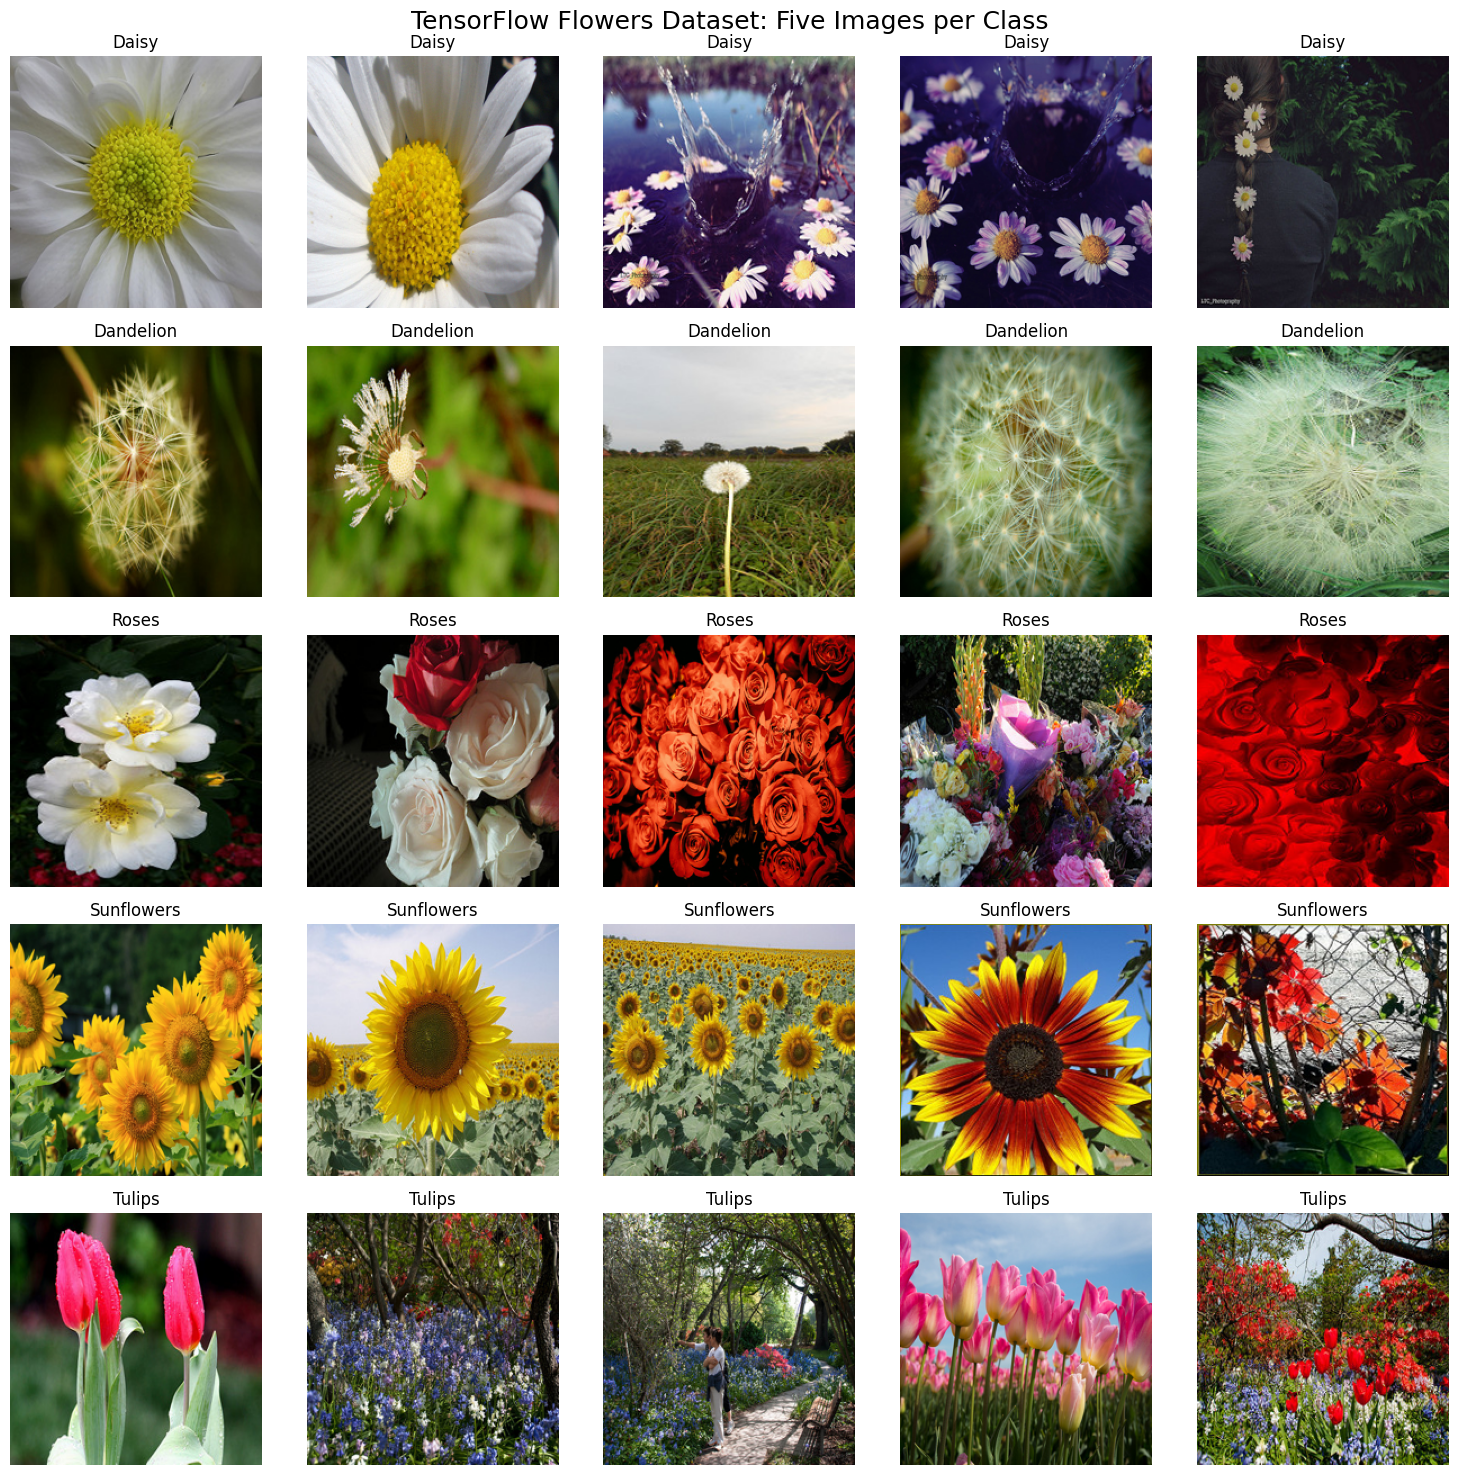

Total images displayed: 25
Image dimensions: 224 x 224 x 3
Saved visualization as plot1.png


In [ ]:

# ==========================================
# DISPLAY 5 IMAGES FROM EACH FLOWER CLASS
# ==========================================

import os
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.utils import get_file
from PIL import Image

# Download and extract the dataset
dataset_url = (
    "https://storage.googleapis.com/download.tensorflow.org/"
    "example_images/flower_photos.tgz"
)

archive_path = get_file(
    "flower_photos.tgz",
    origin=dataset_url,
    extract=True
)

# Find the folder containing all five classes
search_root = os.path.dirname(archive_path)

classes = [
    "daisy",
    "dandelion",
    "roses",
    "sunflowers",
    "tulips"
]

data_dir = None

for root, dirs, files in os.walk(search_root):
    if all(name in dirs for name in classes):
        data_dir = root
        break

if data_dir is None:
    raise FileNotFoundError(
        "Flower dataset folders were not found. "
        "Please check the dataset download."
    )

print("Dataset folder:", data_dir)

# Create a 5 x 5 image grid
fig, axes = plt.subplots(5, 5, figsize=(15, 15))

for row, flower_class in enumerate(classes):

    class_dir = os.path.join(data_dir, flower_class)

    image_files = sorted([
        f for f in os.listdir(class_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    if len(image_files) < 5:
        print("Not enough images in:", flower_class)
        continue

    for col in range(5):

        image_path = os.path.join(
            class_dir, image_files[col]
        )

        image = Image.open(image_path).convert("RGB")
        image = image.resize((224, 224))

        axes[row, col].imshow(image)
        axes[row, col].set_title(
            flower_class.capitalize()
        )
        axes[row, col].axis("off")

plt.suptitle(
    "TensorFlow Flowers Dataset: Five Images per Class",
    fontsize=18
)

plt.tight_layout()
plt.savefig("plot1.png", dpi=300, bbox_inches="tight")
plt.show()

print("Total images displayed: 25")
print("Image dimensions: 224 x 224 x 3")
print("Saved visualization as plot1.png")

